In [17]:
import json
from pathlib import Path
from collections import Counter


TOKENS_TO_COUNT = [
    # HGVS coordinate prefixes
    "c.", "p.", "g.", "m.", "n.", "r.",

    # HGVS operations / structural atoms
    "delins", "del", "dup", "ins", "inv", "con", "fs", "ext", "Ter",

    # rsID lexical prefix
    "rs",

    # Chromosome lexical prefix often seen in genomic coordinates
    "chr",

    # Three-letter amino-acid symbols
    "Ala", "Arg", "Asn", "Asp", "Cys", "Gln", "Glu", "Gly", "His", "Ile",
    "Leu", "Lys", "Met", "Phe", "Pro", "Ser", "Thr", "Trp", "Tyr", "Val",

    # A few common compact protein-change suffixes / frameshift endings
    "*", "=", "_", "+", "-",
]



bpe_tokens_file = Path('../../data/tokenizers/clinvar_allele_bpe/selected_bpe_dna_tokens.txt')
bpe_tokens = []
with bpe_tokens_file.open("r", encoding="utf-8") as f:
    for line in f:
        t = line.strip().upper()
        if not t:
            continue
        bpe_tokens.append(t)
#TOKENS_TO_COUNT = bpe_tokens



resources_dir = Path("../../resources")
top_genes_path = resources_dir / "top_genes.txt"

top_genes = []
with top_genes_path.open("r", encoding="utf-8") as f:
    for line in f:
        gene = line.strip().upper()
        if not gene:
            continue
        top_genes.append(gene)
top_genes.remove('-')
TOKENS_TO_COUNT = top_genes

In [18]:
def count_token_frequencies_jsonl(path: Path, tokens: list[str], name: str) -> Counter:
    if not path.exists():
        raise FileNotFoundError(f"Missing test file: {path}")

    counter = Counter({token: 0 for token in tokens})

    with path.open("r", encoding="utf-8") as f:
        for line_no, line in enumerate(f, start=1):
            line = line.strip()
            if not line:
                continue

            try:
                row = json.loads(line)

                if name == "variantscape":
                    text = row["messages"][2]["content"]
                else:
                    text = row["messages"][1]["content"]

                for token in tokens:
                    counter[token] += text.count(token)

            except json.JSONDecodeError as exc:
                raise ValueError(f"Invalid JSON on line {line_no} of {path}: {exc}") from exc

    return counter

In [19]:
variantscape_path = Path("../../data/processed")
tmvar_path = Path("../../data/processed_tmvar")
varchat_path = Path("../../data/processed_varchat")
bronco_path = Path("../../data/processed_bronco")
hereditary_path = Path("../../data/processed_hereditary_disease_balanced")

path_dict = {
    "variantscape": variantscape_path,
    "tmvar": tmvar_path,
    "varchat": varchat_path,
    "bronco": bronco_path,
    "hereditary": hereditary_path
}

In [21]:
global_counter = Counter({token: 0 for token in TOKENS_TO_COUNT})

for name, path in path_dict.items():
    #print(f"\n{name.capitalize()}")

    dataset_counter = Counter({token: 0 for token in TOKENS_TO_COUNT})

    for ds_split in ["train.jsonl"]: #, "test.jsonl", "val.jsonl"]:
        split_counter = count_token_frequencies_jsonl(
            path / ds_split,
            TOKENS_TO_COUNT,
            name,
        )

        '''print(f"{ds_split}:")
        for token, count in split_counter.items():
            print(f"  {token}: {count}")'''

        dataset_counter.update(split_counter)

    '''print("Dataset total:")
    for token, count in dataset_counter.items():
        print(f"  {token}: {count}")'''

    global_counter.update(dataset_counter)

print("Total tokens: ", len(global_counter))
print("\nAll datasets total:")
for token, count in global_counter.items():
    print(f"  {token}: {count}")

Total tokens:  99

All datasets total:
  TTN: 3
  BRCA2: 3221
  ATM: 180
  NF1: 99
  APC: 28
  BRCA1: 3766
  NEB: 2
  TSC2: 7
  POLE: 6
  RYR1: 0
  DMD: 184
  MSH6: 16
  RYR2: 0
  USH2A: 0
  FBN1: 4
  MSH2: 60
  DICER1: 3
  KMT2D: 0
  ALMS1: 0
  ADGRV1: 0
  PKD1: 13
  SYNE1: 1
  PKHD1: 0
  FANCA: 273
  VPS13B: 1
  PALB2: 305
  DNAH5: 0
  PLEC: 0
  SMARCA4: 4
  DNAH11: 2
  BRIP1: 110
  ALK: 216
  MLH1: 22
  PTCH1: 13
  COL7A1: 8
  CDH23: 0
  FLNC: 0
  CFTR: 11
  DSP: 0
  PMS2: 12
  OBSCN: 0
  POLD1: 4
  MYH7: 35
  TSC1: 0
  DYNC1H1: 0
  ZNF469: 0
  LAMA2: 0
  RECQL4: 11
  MSH3: 1
  EYS: 1
  SCN1A: 35
  BLM: 11
  CDH1: 35
  PRKDC: 2
  APOB: 5
  LRP2: 0
  MYO7A: 0
  SCN5A: 4
  SACS: 0
  MET: 400
  SYNE2: 0
  RAD50: 44
  RTEL1: 0
  LDLR: 11
  MYBPC3: 27
  CHEK2: 279
  LZTR1: 0
  NOTCH1: 20
  BARD1: 87
  DYSF: 0
  ABCA4: 0
  RB1: 19
  CHD7: 0
  CACNA1A: 2
  CEP290: 0
  FLNA: 0
  RET: 34
  AXIN2: 0
  MYH11: 0
  COL5A1: 0
  DYNC2H1: 0
  ANK2: 0
  CACNA1H: 0
  MUTYH: 33
  ATR: 9
  RELN: 0
  PC

/var/folders/57/yk3w62md44z9m6ndy61mkkz80000gn/T/ipykernel_4785/3960493010.py:10: RuntimeWarning: divide by zero encountered in log10
  counts = [np.log10(count) if is_log10 else count for _, count in sorted_items]


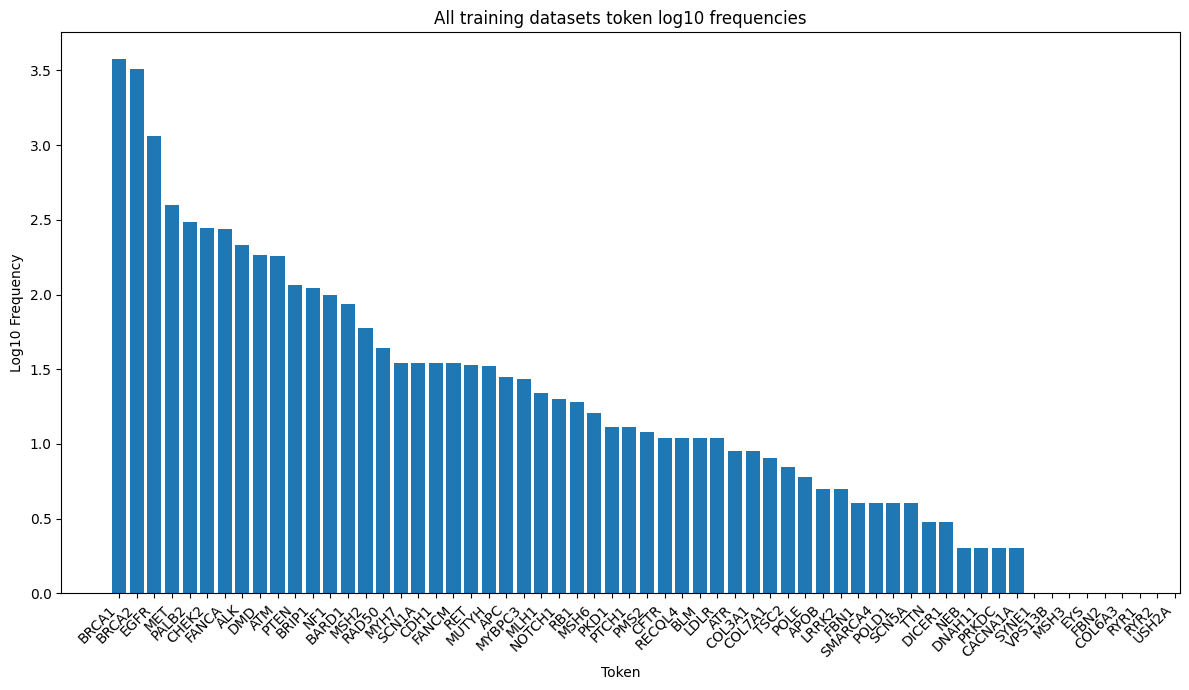

In [22]:
import matplotlib.pyplot as plt
import numpy as np

is_log10 = True

def plot_token_frequencies(counter: Counter, title: str, output_path: Path | None = None):
    sorted_items = sorted(counter.items(), key=lambda x: x[1], reverse=True)

    tokens = [token for token, _ in sorted_items]
    counts = [np.log10(count) if is_log10 else count for _, count in sorted_items]

    plt.figure(figsize=(12, 7))
    plt.bar(tokens, counts)
    plt.xlabel("Token")
    plt.ylabel(f"{'Log10 ' if is_log10 else ''}Frequency")
    plt.title(title)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    if output_path is not None:
        plt.savefig(output_path, dpi=300)

    plt.show()

plot_token_frequencies(
    global_counter,
    title=f"All training datasets token {'log10 ' if is_log10 else ''}frequencies",
    output_path=Path("all_training_datasets_token_frequencies.png"),
)

In [12]:
sorted(global_counter.items(), key=lambda x: x[1], reverse=True)

[('BRCA1', 3769),
 ('BRCA2', 3217),
 ('EGFR', 1078),
 ('MET', 416),
 ('PALB2', 305),
 ('CHEK2', 279),
 ('FANCA', 273),
 ('DMD', 184),
 ('ATM', 180),
 ('ALK', 131),
 ('BRIP1', 110),
 ('PTEN', 95),
 ('BARD1', 87),
 ('MSH2', 60),
 ('NF1', 45),
 ('RAD50', 44),
 ('MYH7', 35),
 ('SCN1A', 35),
 ('CDH1', 35),
 ('FANCM', 35),
 ('RET', 34),
 ('MUTYH', 33),
 ('MYBPC3', 27),
 ('NOTCH1', 27),
 ('APC', 26),
 ('MLH1', 21),
 ('RB1', 20),
 ('MSH6', 16),
 ('PTCH1', 15),
 ('PKD1', 13),
 ('PMS2', 12),
 ('CFTR', 11),
 ('RECQL4', 11),
 ('BLM', 11),
 ('LDLR', 11),
 ('ATR', 9),
 ('COL3A1', 9),
 ('COL7A1', 8),
 ('POLE', 6),
 ('APOB', 5),
 ('LRRK2', 5),
 ('TSC2', 4),
 ('FBN1', 4),
 ('SMARCA4', 4),
 ('POLD1', 4),
 ('SCN5A', 4),
 ('TTN', 3),
 ('DICER1', 3),
 ('NEB', 2),
 ('DNAH11', 2),
 ('PRKDC', 2),
 ('CACNA1A', 2),
 ('SYNE1', 1),
 ('VPS13B', 1),
 ('MSH3', 1),
 ('EYS', 1),
 ('FBN2', 1),
 ('COL6A3', 1),
 ('RYR1', 0),
 ('RYR2', 0),
 ('USH2A', 0),
 ('KMT2D', 0),
 ('ALMS1', 0),
 ('ADGRV1', 0),
 ('PKHD1', 0),
 ('DNAH